# Twin-Delayed DDPG (TD3) Basic Implementation
This file does the recomended implementation of Fujimoto et al.'s **TD3** (2018) as a replacment to the poorly-performing SAC impelmentation given as an example. The primary source of knowledge for implementing this was learnt from OpenAI's 2018 ["Spinning Up" article](https://spinningup.openai.com/en/latest/algorithms/td3.html) and the inspiration for algorithm design was inspired by [CleanRL's JAX implementation](https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/td3_continuous_action_jax.py).

*Note: For my full reference list, please see the bottom of this collab file.*

## Setup

### Dependencies and imports

In [ ]:
%pip install swig rldurham torch

import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""  # disable CUDA (better on Colab/NCC: choose an environment without GPU)
import torch
import rldurham as rld

import gymnasium as gym
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Normal
import numpy as np
import collections, random, copy
import gc

### Hyperparam & Param Configs

Illustrated w/ descriptive comments of theory (for easy reading + to aid my understanding).

In [ ]:
# note: i've set up the hyperparameters in this way so I can easily document what each of them do,
# so when I add new ones I can keep a log of their purpose in this cell for future reference of myself or others

# how much the agent should be caring about future rewards vs immediate ones
# from: bellman equation y = r + ->gamma<- * max Q(s', a')
future_reward_discount= 0.99

# the soft update rate, so a % (e.g. 0.005=0.5%) of weights are leaked every step
# instead of heavy-handedly copying all weights every 1k steps.
# Thus, moving target is very slow & smooth
target_network_smoothing_rate= 0.005

# actor/critics learning rates for adam optimiser
# it's the balance between learning speed to accuracy
actor_learning_speed= 0.0003
critic_learning_speed= 0.0003

# the num of transitions agent looks at in a single gradient update.
# 1 experience=too noisy, whole memory=too slow so balance is found here.
learning_batch_size= 256 # [NOTE]: paper uses 256. Maybe experiment later?

# max transiations agent remebers at a given time
memory_capacity_buffer_limit= 3000000
# target policy smoothing params for robustness (to prevent overfitting)
# from: a'= pi[target](s') + epsilion, where epsilison ~ clip(N(0, sigma), -c,c)
target_action_policy_noise= 0.3 # bit of noise
target_action_noise_clip= 0.5 # + some clipping to next action during critic updates
# together force critics to learn that good actions should still be good with a slight nudge

# this encourages world exploration, keeping the walker shaky enough to try out new movements sometimes.
# That prevents repeats of the same old actions again & again
# from: a = actor(s) + N(0,0.1)
environment_exploration_noise= 0.2
# and then the initial "kick" to get the agent out of a local optimimum where it seems to be stuck limping
#initial_exploration_noise= 0.25
# + how quickly the impact of this initial noise is subdued
#decay_rate_of_noise= 0.999


# the update freq. delay to prevent the "chasing your own tail" issue.
# This is how often the actor is update relativey to the actor
# so policy_delay=2 means the actor is updated every 2 critic updates
policy_delay= 3


# the cnt of training steps per episode (gave up on this hyperparam for now as it's not really needed)
#train_steps_per_epsisode= 100


# this is my relative amount on which I'm trying to reduce the impact of the rewards (both +ve & -ve) to prevent gradient shock (but it wasn't working, so I've dropped the idea for hardcore=False)
#reward_scaling_factor=10.0

# the number of warmup steps to pre-fill the buffer w/ random actions so intial gradients stabilise
# Reference: Soft Actor-Critic (Haarnoja et al. 2018), which uses 10k warmup steps as a standard
initial_warmup_steps= 10000 # (note: I've experimented w/ 25k but that doesn't really help)

# This dictionary now wraps up all the hyperparmams cleanly, having already described them above
hyperparams = {
    "DISCOUNT": future_reward_discount,
    "SMOOTHING_RATE": target_network_smoothing_rate,
    "ACTOR_LR": actor_learning_speed,
    "CRITIC_LR": critic_learning_speed,
    "BATCH_SIZE": learning_batch_size,
    "BUFFER_SIZE": memory_capacity_buffer_limit,
    "POLICY_NOISE": target_action_policy_noise,
    "EXPLORATION_NOISE": environment_exploration_noise,
    #"INITIAL_NOISE": initial_exploration_noise,  # (note: I've experimented with this but w/ mixed results: for now I'll leave the decaying noise off for harcore=False)
    #"NOISE_DECAY" : decay_rate_of_noise,
    "NOISE_CLIP": target_action_noise_clip,
    "POLICY_DELAY": policy_delay,
    #"TRAIN_STEPS": train_steps_per_epsisode,
    #"REWARD_SCALE": reward_scaling_factor,
    "WARMUP_STEPS": initial_warmup_steps
}

In [ ]:
# this is how many runs of the simulation the agent should run, which I set at 2k per coursework request
maximum_episodes= 2000

# this is for how often I want a video to be taken of the robot's running abilities thus far
num_of_episodes_before_recording= 100


params = { # (note: I might extend this later in the hardcore=True mode so keeping this layout, even though its not that necessary right now)
    "MAX_EPISODES": maximum_episodes,
    "RECORD_EVERY_X": 100
}

# TD3 Actor & Critics definitions
First up, I define both my actor and critic networks here. I use TD3 as it was reccomended in the coursework description and seemed indeed appropriate for solving this task after learning about it.

As per the stndard, the critics are learning to predict q-values, & actor is learning to pick whihc actions maximise the min critic estimate, with the target networks slowly tracking the main networks.

In [ ]:
# my actor is responsible for mapping a state to the best possible cointniuos action according to current policy
# I based it off a tailored but standard version of TD3 architecture as reccomended in the coursework description
class Actor(nn.Module):
    def __init__(self, dim_of_obvs, dim_of_action, limit_of_action):
        super(Actor, self).__init__()

        # 1st layer: my intial feature extraction from walker's 24-dim state so it's different motions can be processed and learnt from
        self.feature_vec_input_layer= nn.Linear(dim_of_obvs, 400) # (my main sweep, where my actor network is learning all the basic features)
        #self.first_norm_layer = nn.LayerNorm(400) # I'm removing these for now as they didn't help w/ perfomrance

        # 2nd layer: where all the deep reasoning happens, inc. transforming extracted features
        self.intermediate_hidden_layer= nn.Linear(400, 300) # here the learning should more higher lvl features now
        #self.second_norm_layer = nn.LayerNorm(300)

        # 3rd layer: this part is mapping hidden features to 4-dim action space
        self.output_layer= nn.Linear(300, dim_of_action)
        self.limit_of_action= limit_of_action #motor's physical limit (1.0)

        # orthogonal init for hopefully helping gradients flow clean early on in training
        nn.init.orthogonal_(self.feature_vec_input_layer.weight, gain=np.sqrt(2))
        nn.init.constant_(self.feature_vec_input_layer.bias, 0)

        # I do that orthog init for both input and intermediate layers
        nn.init.orthogonal_(self.intermediate_hidden_layer.weight, gain=np.sqrt(2))
        nn.init.constant_(self.intermediate_hidden_layer.bias, 0)

        # & finally a small final layer init for tanh stability
        nn.init.uniform_(self.output_layer.weight,-3e-3,3e-3)#the 3e-3 was just the standard value I found when reading about these algorithms
        nn.init.uniform_(self.output_layer.bias,-3e-3,3e-3)

    # now I'm processing states through the network in order to produce a deterministic action
    def forward(self, obvs_of_state):
        # 1. Extracting initial features & normalising to prevent gradient explosion
        #x = F.relu(self.first_norm_layer(self.feature_vec_input_layer(obvs_of_state)))
        x= F.relu(self.feature_vec_input_layer(obvs_of_state))

        # 2. Refining features through the deep hidden layer
        #x = F.relu(self.second_norm_layer(self.intermediate_hidden_layer(x)))
        x= F.relu(self.intermediate_hidden_layer(x))

        # 3. Producing raw output
        # then squashing w/ tanh to [-1, 1] range.
        # Finally, scaling to environment's physical limits
        raw_action= self.output_layer(x)
        return self.limit_of_action*torch.tanh(raw_action)

In [ ]:
# my critic's job is to evalulate an action's quality in a given state.
# it gives back a 'Q-Value' estimation, which is the expeted future reward
class Critic_Instance(nn.Module): # (I instantisate 2 of these ones per TD3 architecture [for reducing overestimation bias in value function])
    def __init__(self, dim_of_obvs, dim_of_action):
        super(Critic_Instance, self).__init__()

        # 1st layer: here I'm fusing action & state info
        # i.e. the 24 state dims & 4 action dims are concatenated to a 28-dim input
        self.input_fusion_layer= nn.Linear(dim_of_obvs + dim_of_action, 400) # now my critic is in a position to judge the (state, action) pair
        #self.norm_layer_1 = nn.LayerNorm(400) # same reasioning as in actor, these didn't help w/ performance

        # 2nd layer: all the deep reasoning for estimating cumulative rewards in future
        self.hidden_reasoning_layer= nn.Linear(400, 300)
        #self.norm_layer_2 = nn.LayerNorm(300)

        # 3rd layer: here I'm outputting the scalar Q-value
        self.value_estimation_layer= nn.Linear(300, 1)

        # orthogonal intialisation as per
        nn.init.orthogonal_(self.input_fusion_layer.weight, gain=np.sqrt(2))
        nn.init.constant_(self.input_fusion_layer.bias, 0)
        nn.init.orthogonal_(self.hidden_reasoning_layer.weight, gain=np.sqrt(2))
        nn.init.constant_(self.hidden_reasoning_layer.bias,0)

        # & then I have a small final layer init for q stability
        nn.init.uniform_(self.value_estimation_layer.weight,-3e-3,3e-3)
        nn.init.uniform_(self.value_estimation_layer.bias,-3e-3,3e-3)

    # this predicts Q-value of a state-action pair
    def forward(self, state_observation, action_taken):
        # 1. firstly I'm concatenating state & action vectors into 1 input
        combined_input = torch.cat([state_observation, action_taken], dim=1) # note: dim=1 is batch feature dim

        # 2. nextup, I'm processing it through normalised layers
        #x = F.relu(self.norm_layer_1(self.input_fusion_layer(combined_input)))
        x = F.relu(self.input_fusion_layer(combined_input))

        #x = F.relu(self.norm_layer_2(self.hidden_reasoning_layer(x)))
        x = F.relu(self.hidden_reasoning_layer(x))

        # 3. then the raw scalar value (my critic's "judgement") is returned
        return self.value_estimation_layer(x) # note: higher== its a better action here

# TD3 Memory
The replay buffer is needed as a standard because its breaking correlations between sequential steps (which would cause overfitting to / unlearning of most recent actions). Sampling random batches ensures the 100 transitions come from different episodes & different timepoints, so gradient descent can be properly performed (as it's both independent & identically distributed).

Also, it ensures that good steps can be reused multiple times across different training batches.

In [ ]:
# This is a circular memory system storing agent transitions, allowing the agent to learn from both a diverse & decorrelated set of past experiences
class TrainingMemory:
  def __init__(self, observation_dimensions, action_dimensions, max_capacity):
    # this tracks that circular logic
    # 1st I initialise by preacollating memory
    self.this_write_idx, self.max_capacity, self.counter_of_stored_transitions= 0, max_capacity, 0
    self.obvs, self.actions, self.next_obvs, self.rewards= np.zeros((max_capacity, observation_dimensions)), np.zeros((max_capacity, action_dimensions)), np.zeros((max_capacity, observation_dimensions)), np.zeros((max_capacity, 1))

    # here I store the continuation flags (which==(1-done)) for simplifying bellman eq.
    # idea: target= reward + gamma * next_Q * continuation_flag -> if episode ends, future Q-val is ignored
    self.continuation_flags= np.zeros((max_capacity, 1))

  # here a single experience step is saved in the buffer
  def save_new_transition(self, state, action, next_state, reward, done):
      self.obvs[self.this_write_idx], self.actions[self.this_write_idx], self.next_obvs[self.this_write_idx], self.rewards[self.this_write_idx]= state, action, next_state, reward

      self.continuation_flags[self.this_write_idx]= 1.0-done  # if done=1(True), continuation=0 (False), which stops future reward
      self.this_write_idx= (self.this_write_idx + 1) % self.max_capacity # pointer incremented, loops back to 0 if limit hit (circular logic)

      # total size tracked so sampling's only going to be using valid entries
      self.counter_of_stored_transitions = min(self.counter_of_stored_transitions +1, self.max_capacity) # if full, I'm overwritting oldest data

  # with this function I'm randomly fetching a new batch for my next gradient update
  def grab_batch_sample(self, batch_size):
      # a random indicy is selected from currently stored transitions
      random_indices = np.random.randint(0, self.counter_of_stored_transitions, size=batch_size)

      # now the selected batch is converted to tensors for processing
      return (
          torch.FloatTensor(self.obvs[random_indices]), torch.FloatTensor(self.actions[random_indices]),
          torch.FloatTensor(self.next_obvs[random_indices]), torch.FloatTensor(self.rewards[random_indices]),
          torch.FloatTensor(self.continuation_flags[random_indices]))

# TD3 Agent
The agent is now defined, which is used for overseeing all of the different parts of the RL cycle above, allowing the TD3-powered walker to actually start learning w/ critics/actor combo.

In [ ]:
# this is my td3 agent, whose reposnsibilty is to manage interaction w/ walking environment, actor/critics & training memory buffer
class TD3Agent:
    def __init__(self, environment, hyperparams):
        # prelim of internal counters (how many grad updates + how long last episode was)
        self.training_steps_count= 0
        self.last_episode_steps= 0

        # I'm fetching & storing hyperparams for easy access throughout my agent class
        self.hyperparams= hyperparams

        # environemnt dims & physical constraints are mapped w/ agents internal architecture
        self.env, self.obs_dim, self.act_dim, self.action_max_cap = environment, environment.observation_space.shape[0], environment.action_space.shape[0], float(environment.action_space.high[0])

        # 1st I initialise the actor & critics
        self.actor= Actor(self.obs_dim, self.act_dim, self.action_max_cap) # (i.e. my policy)
        self.critic_1= Critic_Instance(self.obs_dim, self.act_dim) # (& my doulbe q-learning)
        self.critic_2= Critic_Instance(self.obs_dim,self.act_dim)

        # 2nd I setup the target networks (which is 'slow memory') are intialised as copies of the main ones for stabilising training & prevenintg feedback loops because of networks chasing each others noise
        self.actor_target= copy.deepcopy(self.actor)
        self.critic_1_target= copy.deepcopy(self.critic_1)
        self.critic_2_target= copy.deepcopy(self.critic_2)

        # 3rd I configure the adam optimiser (which seems to be standard optimiser choice for this architecure)
        self.actor_optimiser = torch.optim.Adam(self.actor.parameters(), lr=hyperparams["ACTOR_LR"])

        #self.critic_optimiser= torch.optim.Adam(list(self.critic_1.parameters()) + list(self.critic_2.parameters()), lr=hyperparams["CRITIC_LR"]) # [MY OLD VERSION: 1 CRITIC OPTIMISER FOR BOTH CRITICS]
        # (My new vesrion: now w/ seperate critic optimisers, as this improved converging)
        self.critic_1_optimiser= torch.optim.Adam(self.critic_1.parameters(), lr=hyperparams["CRITIC_LR"])
        self.critic_2_optimiser= torch.optim.Adam(self.critic_2.parameters(), lr=hyperparams["CRITIC_LR"])

        # 4th is the storage so the agent can remember past transitions but still learn from decorrelated experience
        self.replay_buffer= TrainingMemory(self.obs_dim, self.act_dim, hyperparams["BUFFER_SIZE"])



    # this acts as a decision maker, querying the actor & adding a bit of exploration noise
    def pick_an_action(self, obvs, noise_std=0.0):
        # 1st I convert obvservation to tensor & add batch dim w/ unsqueeze
        obs_tensor = torch.FloatTensor(obvs).unsqueeze(0)

        # here my deterministic action is fetched from actor
        with torch.no_grad():
            action=self.actor(obs_tensor).numpy()[0]

        # now I add shakiness for exploration
        if noise_std > 0:
            noise= np.random.normal(0, self.action_max_cap*noise_std, size=self.act_dim) # i.e. (N(0, sigma))
            action= (action + noise).clip(-self.action_max_cap, self.action_max_cap)
        return action

    # this is the data collector, interacting w/ the walking env for 1 full episode
    def fireup_episode(self, initial_state, chosen_noise=None):
            state, rwd_from_episode, self.last_episode_steps, done, = initial_state, 0, 0, False

            if chosen_noise is None: # i.e. just go with the 1 fixed noise value instead of dynamic noise decay
                chosen_noise= self.hyperparams["EXPLORATION_NOISE"]

            while not done:
                # 1. a next action is picked (w/ a bit of exploration jitter)
                action= self.pick_an_action(state, noise_std=chosen_noise)

                # 2. now my actor takes a step in the world
                next_state, reward, terminated, truncated, _ = self.env.step(action)
                done= (terminated or truncated)

                # 3. now I handle truncation, as a timeout should count as a fall
                # rule is: if robot falls, flag=0. If time runs out, flag=1
                # My rules for this: iff truncated (time limit), value function shouldn't be penalised (flag=1)
                # but if it terminated (fell), it should be (flag=0)
                terminal_flag= float(terminated)

                # 4. now I save step output to memory
                self.replay_buffer.save_new_transition(state, action, next_state, reward, terminal_flag)

                # 5. & the walker trains immediately after storing its new experience
                self.next_training_step()

                # 6. then finally, I advance everything on w/ update
                state= next_state
                rwd_from_episode += reward
                self.last_episode_steps += 1


            return {'r_sum': rwd_from_episode, 'steps': self.last_episode_steps}





    # here is where the learning happens, using past experiences stored in the experience memory buffer
    def next_training_step(self):
      current_buffer_size= self.replay_buffer.counter_of_stored_transitions
      if current_buffer_size == 0: # i.e. no samples to train w/
          return

      effective_batch_size = min(self.hyperparams["BATCH_SIZE"], current_buffer_size) # gradual warmup


      # Network is updated once per step taken in env.
      self.training_steps_count += 1

      # random batch sampled here for studying
      states, actions, next_states, rewards, continuation_flags= self.replay_buffer.grab_batch_sample(effective_batch_size)


      # next phase: critics are both getting updated
      with torch.no_grad():
          # the target policy is smoothed by adding noise to next action (more robust)
          # Reference: Fujimoto et al. (2018)
          target_noise=(torch.randn_like(actions) * self.hyperparams["POLICY_NOISE"]).clamp(
              -self.hyperparams["NOISE_CLIP"], self.hyperparams["NOISE_CLIP"])
          next_actions=(self.actor_target(next_states) + target_noise).clamp(-self.action_max_cap, self.action_max_cap)

          # this is the fundamental "double-critic" part in my implementation, where the "pessimistic judge" (i.e. lowest val) critic is taken
          target_q1= self.critic_1_target(next_states, next_actions)
          target_q2= self.critic_2_target(next_states, next_actions)
          min_target_q= torch.min(target_q1, target_q2)

          # & this is the bellman target eq. part: target= current reward + gamma + future value
          y_targets= rewards + (continuation_flags*self.hyperparams["DISCOUNT"]*min_target_q)

      # now I estimate the current Q-estimates
      current_q1=self.critic_1(states, actions)
      current_q2=self.critic_2(states, actions)

      # now the critic loss is calculated, which is basically asking how far off from the selected pessimistic judge score it is
      curr_critic_loss = F.mse_loss(current_q1, y_targets) + F.mse_loss(current_q2, y_targets)

      # my 1st critic update
      self.critic_1_optimiser.zero_grad()
      F.mse_loss(current_q1, y_targets).backward(retain_graph=True)
      torch.nn.utils.clip_grad_norm_(self.critic_1.parameters(), 1.0) #critic grad clipping
      self.critic_1_optimiser.step()

      # & my 2nd critic update
      self.critic_2_optimiser.zero_grad()
      F.mse_loss(current_q2, y_targets).backward()
      torch.nn.utils.clip_grad_norm_(self.critic_2.parameters(), 1.0)
      self.critic_2_optimiser.step()



      # and then the delayed actor update phase (which only happens every "POLICY_DELAY" phases, which I set at top of workbook in hyperparms)
      # This is for reducing volatility in value function (Fujimoto et al., 2018)
      if self.training_steps_count % self.hyperparams["POLICY_DELAY"] == 0:
          # the actor loss is moving the actor towards actions that the critic 1 likes
          # (-ve because it's maximising q-val via gradient descent)
          curr_actor_loss= -self.critic_1(states, self.actor(states)).mean()

          self.actor_optimiser.zero_grad()
          curr_actor_loss.backward()
          self.actor_optimiser.step()

          # finally, I'm nudging target softly towards the updated main networks
          self._update_target_networks()

          # & I put in a quick memory cleanup for actor-specific vars
          del curr_actor_loss

      # + a quick memory cleanup for critic/batch variables too
      del states, actions, next_states, rewards, continuation_flags
      del curr_critic_loss


    # then last but not least this is the slow memory update. I'm using polyak avging for stability
    def _update_target_networks(self):
        for main, target in [(self.actor, self.actor_target), (self.critic_1, self.critic_1_target), (self.critic_2, self.critic_2_target)]:
            for main_param, target_param in zip(main.parameters(), target.parameters()):
                target_param.data.copy_(self.hyperparams["SMOOTHING_RATE"] * main_param.data + (1.0 - self.hyperparams["SMOOTHING_RATE"]) * target_param.data)

## Training
Now my environment is prepared for running TD3-backed walking training and wrapped to capture stats, log and videos. Everything from here on out is for kicktstarting all that and outputting the results.

/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


The device is: cpu (as recommended)
actions are continuous with 4 dimensions/#actions
observations are continuous with 24 dimensions/#observations
maximum timesteps is: 2000


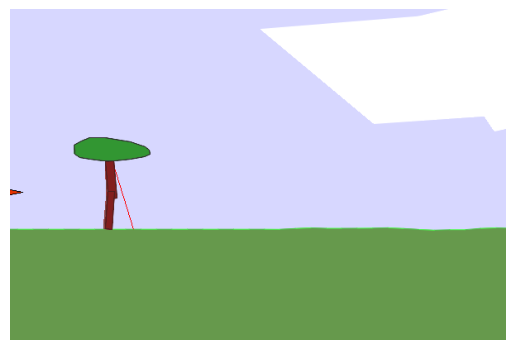

✓ Environment setup complete
✓ Videos will be saved to: videos/xtzv61-td3-agent-video-*.mp4
✓ Logs will be saved to: logs/xtzv61-td3-agent-log.txt


In [ ]:
# this code is all the standard env setup logic, basically the same from the template
MY_DUR_USERNAME= "xtzv61"

# base env creation
base_env = rld.make("rldurham/Walker", render_mode="rgb_array", hardcore=False)

recorder = rld.Recorder(
    base_env,
    smoothing=10,
    video=True,
    video_folder="videos",
    video_prefix=f"{MY_DUR_USERNAME}-td3-agent-video",
    logs=True,
)

# normalising raw env (but most of these didn't atcually help so I got rid for hardcore=False)
env = gym.wrappers.FlattenObservation(recorder) # Ensuring generic compatibility
#env= gym.wrappers.NormalizeObservation(env) #this is for normalising state to mean 0, std 1
#env= gym.wrappers.TransformObservation(env, lambda observation: np.clip(observation, -10, 10)) # this clip supposedly provides a bit more stability
#env= gym.wrappers.NormalizeReward(env) # this scales rewards to mean 0, std 1 (for critic stability) but I'm not using it right now
#env= gym.wrappers.TransformReward(env, lambda r: np.clip(r, -10, 10)) # & finally reward clipping, which also isn't working out currently in this mode

# device (i.e. C/G PU)
rld.check_device()

# env info
rld.env_info(recorder, print_out=True)

# seeding stuff
seed, observation, info = rld.seed_everything(42, recorder)

# initial observation rendered
rld.render(recorder)

recorder.video = False # just initially turned off


print("✓ Environment setup complete")
print(f"✓ Videos will be saved to: videos/{MY_DUR_USERNAME}-td3-agent-video-*.mp4")
print(f"✓ Logs will be saved to: logs/{MY_DUR_USERNAME}-td3-agent-log.txt")

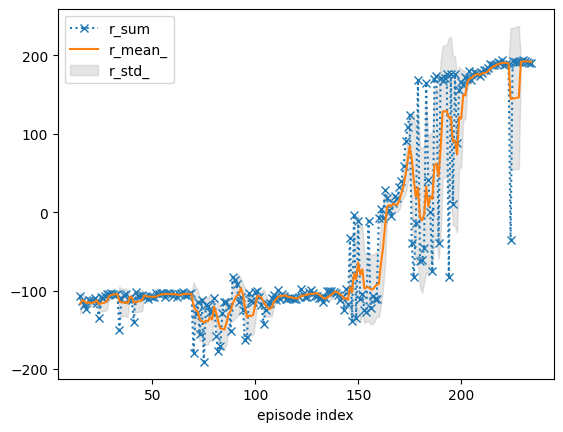

In [ ]:
# this code intialises & trains the agent, again very similar to the template file provided
agent = TD3Agent(env, hyperparams)
tracker = rld.InfoTracker()

# Ensure recording is off initially
recorder.video = False

# here I'm prefilling buffer w/ random actions for initial grad stabilising
obs, _ = env.reset()
for _ in range(hyperparams["WARMUP_STEPS"]): # 10k steps warmup
    action = env.action_space.sample()
    next_obs, reward, terminated, truncated, _ = env.step(action)
    done = terminated or truncated
    agent.replay_buffer.save_new_transition(obs, action, next_obs, reward, float(terminated))
    obs = next_obs
    if done: obs, _ = env.reset()

print(f"Firing up TD3 agent training for {params['MAX_EPISODES']} episodes...\n")

# here's all the main training
for episode in range(params['MAX_EPISODES']):
    record_this_episode = (episode + 1) % params["RECORD_EVERY_X"] == 0

    # recording off when just finished recording an epsiode
    if not record_this_episode and recorder.video:
        recorder.video = False

    # & iff needed it's enabled
    if record_this_episode:
        recorder.video = True


    state, _ = env.reset()

    # standard const 0.1 noise val
    current_noise = hyperparams["EXPLORATION_NOISE"] # max(hyperparams["EXPLORATION_NOISE"], hyperparams["INITIAL_NOISE"] * (hyperparams["NOISE_DECAY"] ** episode))
    # [MY OLD METHOD, kept in for interchangibility] noise here is decayed over episodes, but never goes below the standard 0.1 line

    episode_info = agent.fireup_episode(state, chosen_noise=current_noise)

    recorder.add_stats(episode_info, ignore_existing=True)
    tracker.track(episode_info)

    if (episode + 1) % 10 == 0:
        print(f"Episode {episode + 1}/{params['MAX_EPISODES']}")
        tracker.plot(r_mean_=True, r_std_=True, r_sum=dict(linestyle=':', marker='x'))
        gc.collect()


# again similar to the template, this is all the logging and debugging logic
print("Closing environment now...")
env.close()
recorder.close()
recorder.write_log(folder="logs", file=f"{MY_DUR_USERNAME}-td3-agent-log.txt")

print(f"\n{'/' * 100}")
print("Training's now done.")
print(f"Videos are all saved, find in directory: videos/{MY_DUR_USERNAME}-td3-agent-video-xyz.mp4")
print(f"Similarly, logs are saved in directory: logs/{MY_DUR_USERNAME}-td3-agent-log.txt")

# References
[1] S. Fujimoto, van Hoof, and D. Meger, “Addressing Function Approximation Error in Actor-Critic Methods,” arXiv.org, 2018. https://arxiv.org/abs/1802.09477 (accessed Feb. 13, 2026).
‌

[2] “Twin Delayed DDPG — Spinning Up documentation,” Openai.com, 2018. https://spinningup.openai.com/en/latest/algorithms/td3.html (accessed Feb. 13, 2026).
‌

[3] “cleanrl/cleanrl/td3_continuous_action_jax.py at master · vwxyzjn/cleanrl,” GitHub, 2025. https://github.com/vwxyzjn/cleanrl/blob/master/cleanrl/td3_continuous_action_jax.py (accessed Feb. 13, 2026).
‌

[4] J. L. Ba, J. R. Kiros, and G. E. Hinton, “Layer Normalization,” arXiv.org, 2016. https://arxiv.org/abs/1607.06450 (accessed Feb. 13, 2026).
‌